# Preselection Cuts and Cleaning
Before we work with any of the data, we run 2 preselection cuts based on known limitations / features of the datasets.
**Preselection cuts**
1. Calorimeter barrel/end-cap transition region 1.37 < |η| < 1.52. We cut on pseudorapidity in the barrel/end cap transition region because it is a known, poorly measured region.
2. Transverese momentum. We cut on transverse momentum because it is known that the leading (sub-leading) photon candidate is required to have ET > 40 GeV (30GeV). Therefore we keep photons where photon_pt[0]>40000 MeV and photon_pt[1]>30000 MeV

In [1]:
import awkward as ak
import uproot 
import numpy as np


import sys
sys.path.append("../src")
import preselection
from preselection import cut_photon_eta_transition, cut_photon_pt
import features
from features import calc_myy
import plotting
from plotting import plot_data

branches = [
    "photon_n", "trigP", "photon_pt", "photon_eta", "photon_phi", 
    "photon_E", "photon_isTightID", "photon_ptcone30", "photon_etcone20",

    "mcWeight", "scaleFactor_PILEUP", "scaleFactor_PHOTON",
    "scaleFactor_PhotonTRIGGER", "XSection", "SumWeights",

    "jet_n", "jet_pt", "jet_eta", "jet_phi", "jet_jvt"
]

In [2]:
arrays_A = uproot.open("../data/raw/data_A.GamGam.root:mini").arrays(branches, library="ak")
arrays_B = uproot.open("../data/raw/data_B.GamGam.root:mini").arrays(branches, library="ak")
arrays_C = uproot.open("../data/raw/data_C.GamGam.root:mini").arrays(branches, library="ak")
arrays_D = uproot.open("../data/raw/data_D.GamGam.root:mini").arrays(branches, library="ak")

cutflow = {}
cutflow["all events"] = len(arrays_A) + len(arrays_B) + len(arrays_C) + len(arrays_D)


arrays_A = arrays_A[cut_photon_eta_transition(arrays_A.photon_eta)]
arrays_B = arrays_B[cut_photon_eta_transition(arrays_B.photon_eta)]
arrays_C = arrays_C[cut_photon_eta_transition(arrays_C.photon_eta)]
arrays_D = arrays_D[cut_photon_eta_transition(arrays_D.photon_eta)]
cutflow["photon eta crack"] = len(arrays_A) + len(arrays_B) + len(arrays_C) + len(arrays_D)


arrays_A = arrays_A[cut_photon_pt(arrays_A.photon_pt)]
arrays_B = arrays_B[cut_photon_pt(arrays_B.photon_pt)]
arrays_C = arrays_C[cut_photon_pt(arrays_C.photon_pt)]
arrays_D = arrays_D[cut_photon_pt(arrays_D.photon_pt)]
cutflow["photon pT"] = len(arrays_A) + len(arrays_B) + len(arrays_C) + len(arrays_D)


out_path = "../data/processed/data_A_preselection.root"
with uproot.recreate(out_path) as f:
    f["mini"] = {name: arrays_A[name] for name in arrays_A.fields}

out_path = "../data/processed/data_B_preselection.root"
with uproot.recreate(out_path) as f:
    f["mini"] = {name: arrays_B[name] for name in arrays_B.fields}

out_path = "../data/processed/data_C_preselection.root"
with uproot.recreate(out_path) as f:
    f["mini"] = {name: arrays_C[name] for name in arrays_C.fields}

out_path = "../data/processed/data_D_preselection.root"
with uproot.recreate(out_path) as f:
    f["mini"] = {name: arrays_D[name] for name in arrays_D.fields}


for name, n in cutflow.items():
    print(f"{name:20s} {n:>10d}  ({n / cutflow['all events']:.1%})")

all events              7798424  (100.0%)
photon eta crack        7421633  (95.2%)
photon pT               4529227  (58.1%)


In an ideal isotropic distribution (photons fly off in random directions), ~3% of photon directions have a modulus eta in the range 1.37 < |η| < 1.52. This is roughly the polar angles of 25°-29° from either direction along the beam. With two photons per event, the chance that at least one photon hits the region is about 6%. This makes our 95% keep rate for this cut reasonable. 

It is known that the diphoton trigger becomes efficient at ~35GeV for the leading photon and ~25GeV for the subleading photons. We use thresholds of 40GeV and 30GeV to provide a 5GeV margin. Because the photon p_T spectrum falls steeply, that 5GeV margin means the two preselection cuts together retain about 58% of the original events. 

## Cleaning

In [3]:
def clean_sample(label, events):
    mass = calc_myy(
        events.photon_pt,
        events.photon_eta,
        events.photon_phi,
        events.photon_E,
    )

    bad = ~np.isfinite(ak.to_numpy(mass))
    photons_removed = int(ak.sum(ak.num(events.photon_pt[bad], axis=1)))

    print(
        f"{label}: {bad.sum()} events removed, "
        f"{photons_removed} photons removed"
    )
    if bad.any():
        print("  Example affected photon pT:",
              ak.to_list(events.photon_pt[bad][:5]))

    valid = ~bad
    return events[valid], mass[valid]


arrays_A, myy_A = clean_sample("A", arrays_A)
arrays_B, myy_B = clean_sample("B", arrays_B)
arrays_C, myy_C = clean_sample("C", arrays_C)
arrays_D, myy_D = clean_sample("D", arrays_D)

A: 0 events removed, 0 photons removed
B: 0 events removed, 0 photons removed
C: 1 events removed, 3 photons removed
  Example affected photon pT: [[45590.296875, 35390.046875, 34599.05078125]]
D: 0 events removed, 0 photons removed


/Users/alejandrowhitehair/Projects/higgs-diphoton/notebooks/../src/features.py:18: UserWarning: Invalid or negative diphoton mass-squared found; returning NaN for those events.
  warnings.warn("Invalid or negative diphoton mass-squared found; returning NaN for those events.")


## Preselection A - (Background Training Data)

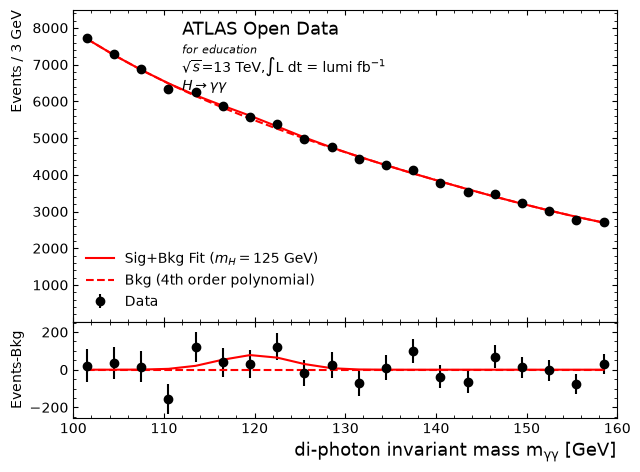

In [4]:
plot_data(myy_A)

## Preselection B

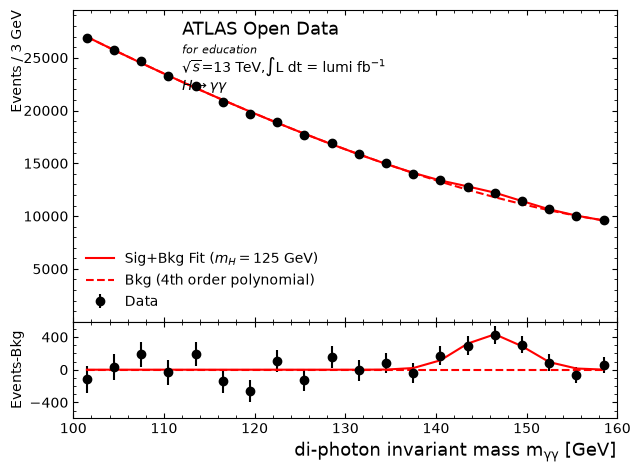

In [5]:
plot_data(myy_B)

## Preselection C

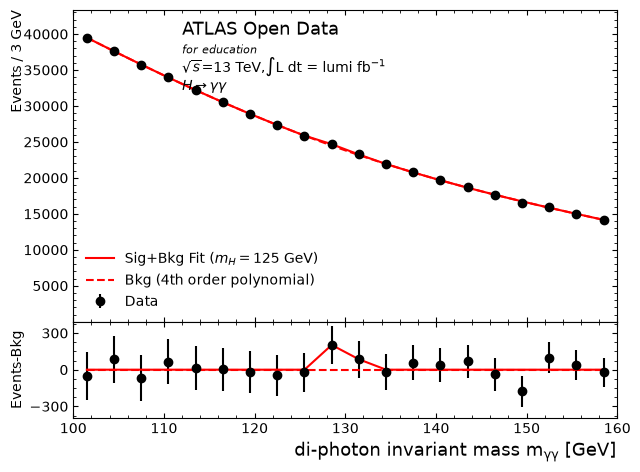

In [6]:
plot_data(myy_C)

## Preselection D

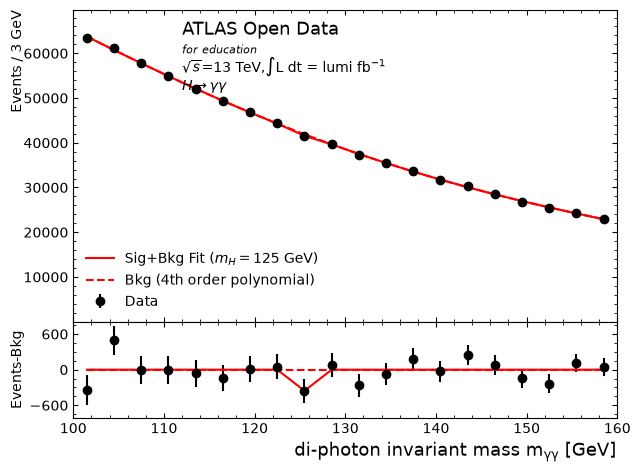

In [7]:
plot_data(myy_D)

## Preselection ALL

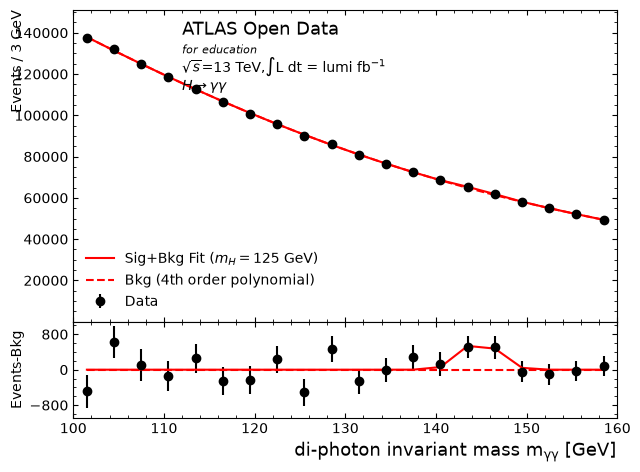

In [8]:
arrays_all = ak.concatenate([arrays_A, arrays_B, arrays_C, arrays_D], axis=0)

myy_all = calc_myy(
    arrays_all.photon_pt,
    arrays_all.photon_eta,
    arrays_all.photon_phi,
    arrays_all.photon_E,
)
plot_data(myy_all)